In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('Housing.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Mean Squared Error: 3562004338819.114

R2 Score: 0.29529036788351204

Cross Validation Score: [  -7.36801725  -15.98594868  -17.04025724  -46.13166193  -63.67111068
 -129.64589502 -100.24197731 -220.84004674 -179.83822103  -33.38578913]

Average Score: -81.41489250096387


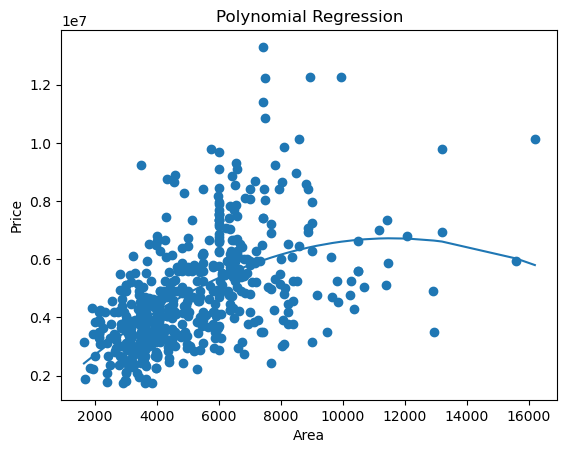

In [5]:
X = df[['area']]
Y = df['price']

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42
)
model = make_pipeline(
    PolynomialFeatures(degree = 2),
    LinearRegression()
)
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)
print(f'\nMean Squared Error: {mean_squared_error(Y_test, Y_pred)}')
print(f'\nR2 Score: {r2_score(Y_test, Y_pred)}')
scores = cross_val_score(
    model,
    X,
    Y,
    cv = 10,
    scoring = 'r2'
)
print(f'\nCross Validation Score: {scores}')
print(f'\nAverage Score: {scores.mean()}')

plt.scatter(X, Y)
X_sorted = X.sort_values(by = 'area')
Y_sorted_pred = model.predict(X_sorted)
plt.plot(X_sorted, Y_sorted_pred)
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Polynomial Regression')
plt.show()